# Project 13: CNN Architecture Comparison
## Simple CNN vs. ResNet-style CNN on CIFAR-10

**NAME:** **Prakruthi BR**

**REG NO:** **2411021240038**

**SUBJECT:** **Deep Learning**

**Goal:** Train two convolutional neural network architectures on the *same image dataset* and compare their accuracy, complexity, confusion matrices, classification reports, and prediction errors.

### What this notebook does
1. Loads and prepares CIFAR-10 (10 classes of small colour images).
2. Builds a **Simple CNN** and a **ResNet-style CNN** with residual connections.
3. Trains and evaluates both models on the same data.
4. Compares accuracy, parameter count, training time, confusion matrices, and classification reports.
5. Shows examples of incorrect predictions and writes a brief results summary.

**Designed for Google Colab:** Open the `.ipynb` file in Google Colab. For faster training, choose **Runtime → Change runtime type → T4 GPU** if available. The notebook works on CPU too, but training will be slower.

> **Reproducibility note:** This notebook uses a fixed random seed. Results can still vary slightly across hardware and TensorFlow versions. The default quick-run setting uses a subset so the assignment finishes in a reasonable time; you can switch to the full dataset for a more thorough experiment.

## 1. Import libraries and set reproducibility

TensorFlow/Keras builds and trains the neural networks. NumPy handles arrays, Matplotlib displays graphs, and scikit-learn provides the confusion matrix and classification report.

The notebook uses libraries commonly available in Google Colab. If any import fails, run the installation cell below once and restart the runtime if Colab asks you to.

In [1]:
# Install only the main packages needed for this assignment
%pip -q install tensorflow scikit-learn matplotlib seaborn

In [2]:
import os
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from tensorflow.keras import layers, models
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score
)

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)
print("Available GPU devices:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.21.0
Available GPU devices: []


## 2. Load and prepare the CIFAR-10 dataset

CIFAR-10 contains 60,000 colour images of size 32×32, split into 50,000 training images and 10,000 test images. Each image belongs to one of 10 classes.

**Why use one dataset for both models?** It keeps the comparison fair: any performance difference is more likely to come from the model architecture rather than from different data.

By default, `QUICK_RUN = True` selects a reproducible subset for faster training in Colab. Set it to `False` to use the full training and test sets. Pixel values are scaled from 0–255 to 0–1, which helps neural-network training.

In [3]:
# Change to False to train on the full CIFAR-10 dataset.
QUICK_RUN = True
TRAIN_SAMPLES = 5000
TEST_SAMPLES = 1000
EPOCHS = 3
BATCH_SIZE = 128

class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

(x_train, y_train), (x_test, y_test) = tf.keras.datasets.cifar10.load_data()
y_train = y_train.squeeze()
y_test = y_test.squeeze()

if QUICK_RUN:
    # Fixed seed makes the selected subset reproducible.
    rng = np.random.default_rng(SEED)
    train_idx = rng.choice(len(x_train), TRAIN_SAMPLES, replace=False)
    test_idx = rng.choice(len(x_test), TEST_SAMPLES, replace=False)
    x_train, y_train = x_train[train_idx], y_train[train_idx]
    x_test, y_test = x_test[test_idx], y_test[test_idx]

x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

print("Training images:", x_train.shape, "| Test images:", x_test.shape)
print("Number of classes:", len(class_names))

Training images: (5000, 32, 32, 3) | Test images: (1000, 32, 32, 3)
Number of classes: 10


### View sample images

This grid lets you check that the dataset loaded correctly and see examples from different categories.

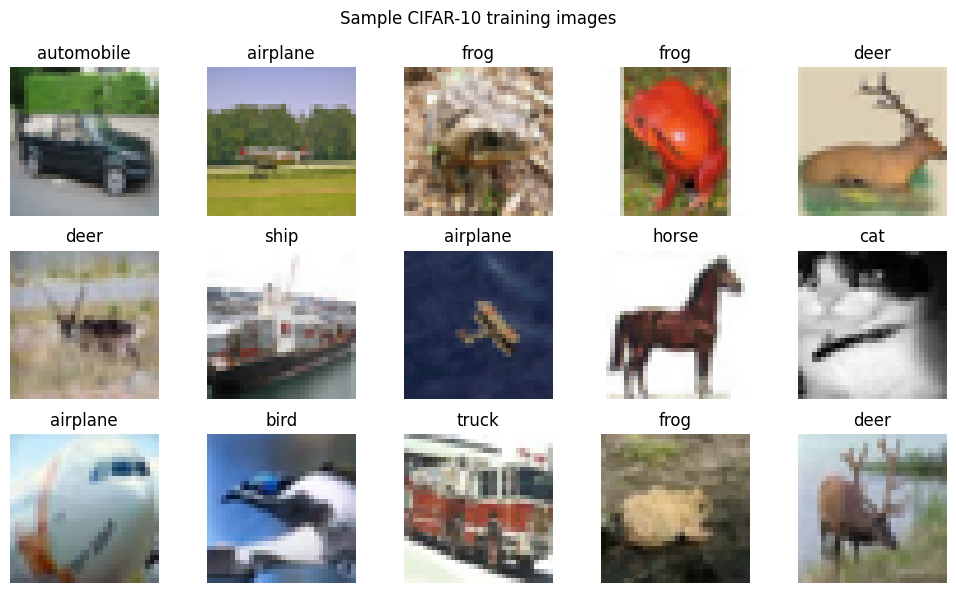

In [4]:
plt.figure(figsize=(10, 6))
for i in range(15):
    plt.subplot(3, 5, i + 1)
    plt.imshow(x_train[i])
    plt.title(class_names[int(y_train[i])])
    plt.axis("off")
plt.suptitle("Sample CIFAR-10 training images")
plt.tight_layout()
plt.show()

## 3. Model A — Simple CNN

A CNN learns visual patterns using convolution filters. Early layers often learn simple patterns such as edges, while deeper layers can learn more complex shapes.

The simple model below contains convolution, max-pooling, dropout, and dense layers. It is our baseline architecture. It has fewer layers and no residual connections, making it relatively straightforward to understand.

In [5]:
def build_simple_cnn(input_shape=(32, 32, 3), num_classes=10):
    model = models.Sequential(name="Simple_CNN")
    model.add(layers.Input(shape=input_shape))

    model.add(layers.Conv2D(32, 3, padding="same", activation="relu"))
    model.add(layers.MaxPooling2D())
    model.add(layers.Conv2D(64, 3, padding="same", activation="relu"))
    model.add(layers.MaxPooling2D())
    model.add(layers.Conv2D(128, 3, padding="same", activation="relu"))
    model.add(layers.GlobalAveragePooling2D())

    model.add(layers.Dropout(0.3))
    model.add(layers.Dense(64, activation="relu"))
    model.add(layers.Dense(num_classes, activation="softmax"))

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

simple_cnn = build_simple_cnn()
simple_cnn.summary()

Model: "Simple_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 102,154 (399.04 KB)

 Trainable params: 102,154 (399.04 KB)

 Non-trainable params: 0 (0.00 B)

### Code explanation — Simple CNN
- `Conv2D`: learns image features such as edges, textures, and shapes.
- `MaxPooling2D`: reduces feature-map size and computation.
- `GlobalAveragePooling2D`: converts feature maps into a compact feature vector.
- `Dropout(0.3)`: randomly drops some activations during training to help reduce overfitting.
- `Dense`: combines learned features to make a class prediction.
- `softmax`: outputs a probability for each of the 10 classes.
- `sparse_categorical_crossentropy`: suitable because labels are integer class IDs (0–9).
- `Adam`: adjusts model weights to reduce prediction loss.

## 4. Model B — ResNet-style CNN

ResNet (Residual Network) is a well-known CNN architecture. Its key idea is a **skip/residual connection**: the input to a block is added to the block's learned output. This gives information and gradients a more direct path through the network, which can make deeper networks easier to train.

For this assignment, we implement a compact ResNet-style model from scratch. This avoids downloading pretrained weights and makes the notebook self-contained. It demonstrates the main residual-connection idea, but it is **not a full canonical ResNet-18 or ResNet-50 implementation**.

In [6]:
def residual_block(x, filters, stride=1):
    shortcut = x

    # Main path: two convolution layers
    x = layers.Conv2D(
        filters, 3, strides=stride, padding="same", use_bias=False
    )(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)

    x = layers.Conv2D(
        filters, 3, strides=1, padding="same", use_bias=False
    )(x)
    x = layers.BatchNormalization()(x)

    # Match shortcut dimensions when filters or spatial size changes
    if stride != 1 or shortcut.shape[-1] != filters:
        shortcut = layers.Conv2D(
            filters, 1, strides=stride, padding="same", use_bias=False
        )(shortcut)
        shortcut = layers.BatchNormalization()(shortcut)

    x = layers.Add()([x, shortcut])  # residual / skip connection
    x = layers.Activation("relu")(x)
    return x


def build_resnet_style(input_shape=(32, 32, 3), num_classes=10):
    inputs = layers.Input(shape=input_shape)
    x = layers.Conv2D(32, 3, padding="same", use_bias=False)(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)

    x = residual_block(x, 32)
    x = residual_block(x, 64, stride=2)
    x = residual_block(x, 128, stride=2)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(num_classes, activation="softmax")(x)

    model = models.Model(inputs, outputs, name="ResNet_Style_CNN")
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

resnet_style = build_resnet_style()
resnet_style.summary()

Model: "ResNet_Style_CNN"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 32, 32, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 32, 32,    │        864 │ input_layer_1[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 32, 32,    │        128 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 32, 32,    │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 32, 32,    │      9,216 │ activation[0][0]  │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        128 │ conv2d_4[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 32, 32,    │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 32, 32,    │      9,216 │ activation_1[0][… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        128 │ conv2d_5[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 32, 32,    │          0 │ batch_normalizat… │
│                     │ 32)               │            │ activation[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 32, 32,    │          0 │ add[0][0]         │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 16, 16,    │     18,432 │ activation_2[0][… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 16, 16,    │        256 │ conv2d_6[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 16, 16,    │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, 16, 16,    │     36,864 │ activation_3[0][… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_8 (Conv2D)   │ (None, 16, 16,    │      2,048 │ activation_2[0][… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 16, 16,    │        256 │ conv2d_7[0][0]  

 Total params: 309,994 (1.18 MB)

 Trainable params: 308,650 (1.18 MB)

 Non-trainable params: 1,344 (5.25 KB)

### Code explanation — ResNet-style CNN
- The initial convolution extracts basic features from the image.
- Each `residual_block` has two convolutions and batch-normalization layers.
- `shortcut` keeps the block input so it can be added back to the learned features.
- A 1×1 convolution adjusts the shortcut when the number of channels or image size changes.
- `Add()` performs the residual addition.
- `stride=2` reduces spatial dimensions while increasing the number of feature channels.
- Global average pooling and a softmax output produce the final 10-class prediction.

**Important:** Both models use the same dataset, image resolution, optimizer family, learning rate, epoch count, and evaluation test set. Their layer structures differ, which is the main focus of the comparison.

## 5. Train both models

The next cell trains the two models one after another and records training time. Training time depends on whether Colab provides a GPU, so your values may differ from someone else's results.

In [8]:
history_data = {}
trained_models = {}
training_times = {}

for model_name, model in [
    ("Simple CNN", simple_cnn),
    ("ResNet-style CNN", resnet_style)
]:
    print("\\n" + " " * 65)
    print("Training:", model_name)
    start_time = time.time()

    history = model.fit(
        x_train, y_train,
        validation_split=0.1,
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        verbose=1
    )

    elapsed = time.time() - start_time
    history_data[model_name] = history
    trained_models[model_name] = model
    training_times[model_name] = elapsed

    print(f"{model_name} training time: {elapsed:.1f} seconds")

\n                                                                 
Training: Simple CNN
Epoch 1/3
36/36 ━━━━━━━━━━━━━━━━━━━━ 15s 398ms/step - accuracy: 0.2082 - loss: 2.0609 - val_accuracy: 0.2660 - val_loss: 1.9051
Epoch 2/3
36/36 ━━━━━━━━━━━━━━━━━━━━ 17s 311ms/step - accuracy: 0.2471 - loss: 1.9272 - val_accuracy: 0.2840 - val_loss: 1.8333
Epoch 3/3
36/36 ━━━━━━━━━━━━━━━━━━━━ 21s 309ms/step - accuracy: 0.2711 - loss: 1.8893 - val_accuracy: 0.2980 - val_loss: 1.7981
Simple CNN training time: 52.8 seconds
\n                                                                 
Training: ResNet-style CNN
Epoch 1/3
36/36 ━━━━━━━━━━━━━━━━━━━━ 69s 2s/step - accuracy: 0.2782 - loss: 1.9571 - val_accuracy: 0.1280 - val_loss: 2.3498
Epoch 2/3
36/36 ━━━━━━━━━━━━━━━━━━━━ 81s 2s/step - accuracy: 0.3782 - loss: 1.6888 - val_accuracy: 0.1220 - val_loss: 2.8063
Epoch 3/3
36/36 ━━━━━━━━━━━━━━━━━━━━ 82s 2s/step - accuracy: 0.4493 - loss: 1.5256 - val_accuracy: 0.1120 - val_loss: 3.0208
ResNet-style CNN t

## 6. Compare training and validation accuracy

Accuracy is the fraction of predictions that are correct. Training accuracy measures performance on training examples; validation accuracy measures performance on a held-out portion of the training data during training.

If training accuracy keeps rising while validation accuracy stops improving or falls, the model may be overfitting.

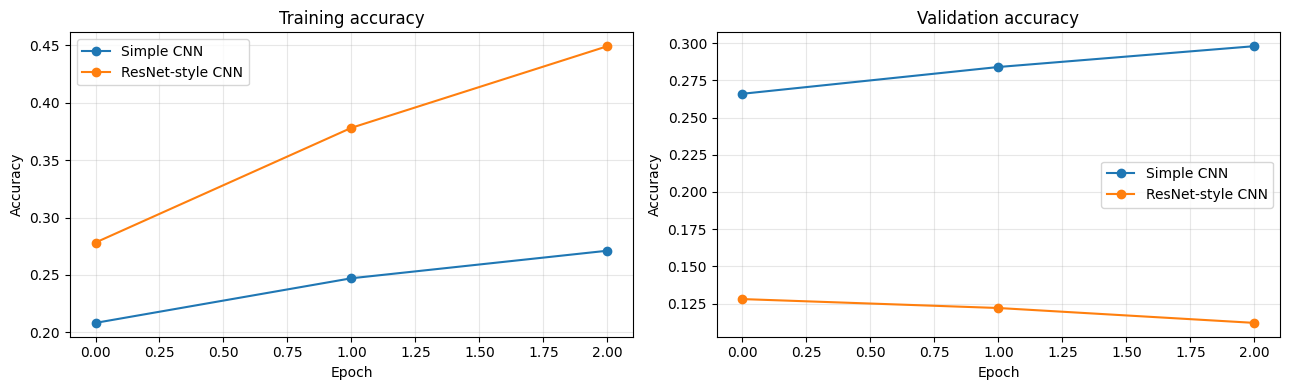

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for model_name, history in history_data.items():
    axes[0].plot(history.history["accuracy"], marker="o", label=model_name)
    axes[1].plot(history.history["val_accuracy"], marker="o", label=model_name)

axes[0].set_title("Training accuracy")
axes[1].set_title("Validation accuracy")
for ax in axes:
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Accuracy")
    ax.grid(True, alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

## 7. Evaluate on the same test set

The test set is not used to update model weights. It provides a common set of unseen images for comparing the models.

We calculate test loss, test accuracy, predicted class labels, number of trainable/non-trainable parameters, and training duration.

In [10]:
results = []
predictions = {}

for model_name, model in trained_models.items():
    test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
    probabilities = model.predict(x_test, batch_size=BATCH_SIZE, verbose=0)
    y_pred = np.argmax(probabilities, axis=1)
    predictions[model_name] = y_pred

    results.append({
        "Model": model_name,
        "Test accuracy (%)": round(float(test_acc) * 100, 2),
        "Test loss": round(float(test_loss), 4),
        "Total parameters": int(model.count_params()),
        "Training time (seconds)": round(training_times[model_name], 1)
    })

results_df = pd.DataFrame(results).sort_values(
    "Test accuracy (%)", ascending=False
).reset_index(drop=True)

display(results_df)

,Model,Test accuracy (%),Test loss,Total parameters,Training time (seconds)
0,Simple CNN,28.0,1.8316,102154,52.8
1,ResNet-style CNN,12.7,2.9678,309994,253.5


### How to interpret the comparison table
- **Test accuracy:** higher is better, but accuracy alone does not tell us which classes are confused.
- **Test loss:** lower generally indicates better probabilistic predictions.
- **Total parameters:** indicates model size/parameter complexity; it is not the only measure of computational cost.
- **Training time:** depends on the model, hardware, batch size, and current Colab availability.

Do not assume the ResNet-style model must win. Its skip connections can help optimization, but performance depends on data size, model design, and training settings.

## 8. Confusion matrices

A confusion matrix compares actual classes (rows) with predicted classes (columns). The diagonal contains correct predictions. Off-diagonal cells show which classes the model mixes up.

We show both matrices with the same class order and test examples so the comparison is fair.

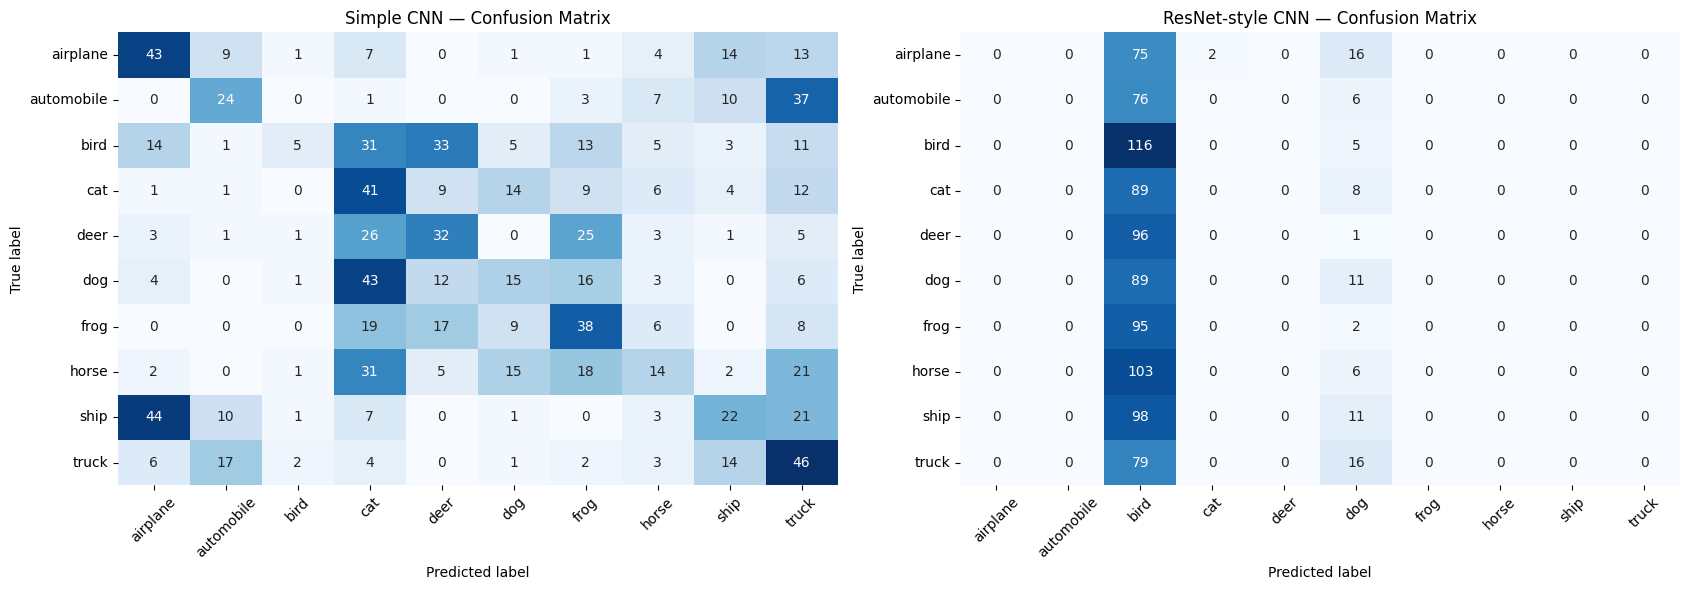

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(17, 6))

for ax, model_name in zip(axes, ["Simple CNN", "ResNet-style CNN"]):
    cm = confusion_matrix(y_test, predictions[model_name], labels=np.arange(10))
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
        xticklabels=class_names, yticklabels=class_names
    )
    ax.set_title(f"{model_name} — Confusion Matrix")
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")
    ax.tick_params(axis="x", rotation=45)
    ax.tick_params(axis="y", rotation=0)

plt.tight_layout()
plt.show()

## 9. Classification reports

Precision, recall, and F1-score provide more detail than accuracy alone.

- **Precision:** of the images predicted as a class, how many truly belong to that class?
- **Recall:** of all real images in a class, how many did the model correctly find?
- **F1-score:** the harmonic mean of precision and recall.
- **Support:** number of test examples belonging to that class.

The `zero_division=0` setting keeps the report from raising warnings if a model never predicts one of the classes.

In [12]:
for model_name in ["Simple CNN", "ResNet-style CNN"]:
    print("\\n" + "=" * 70)
    print(f"Classification report: {model_name}")
    print(classification_report(
        y_test,
        predictions[model_name],
        labels=np.arange(10),
        target_names=class_names,
        digits=3,
        zero_division=0
    ))

\n======================================================================
Classification report: Simple CNN
              precision    recall  f1-score   support

    airplane      0.368     0.462     0.410        93
  automobile      0.381     0.293     0.331        82
        bird      0.417     0.041     0.075       121
         cat      0.195     0.423     0.267        97
        deer      0.296     0.330     0.312        97
         dog      0.246     0.150     0.186       100
        frog      0.304     0.392     0.342        97
       horse      0.259     0.128     0.172       109
        ship      0.314     0.202     0.246       109
       truck      0.256     0.484     0.335        95

    accuracy                          0.280      1000
   macro avg      0.304     0.291     0.268      1000
weighted avg      0.304     0.280     0.260      1000

\n======================================================================
Classification report: ResNet-style CNN
              precisi

## 10. Inspect incorrect predictions

This section displays a small sample of mistakes made by each model. Looking at errors can reveal visually similar classes (for example, cats and dogs) that are difficult to distinguish.

A wrong prediction does not automatically mean the model is defective; low-resolution images can be ambiguous.

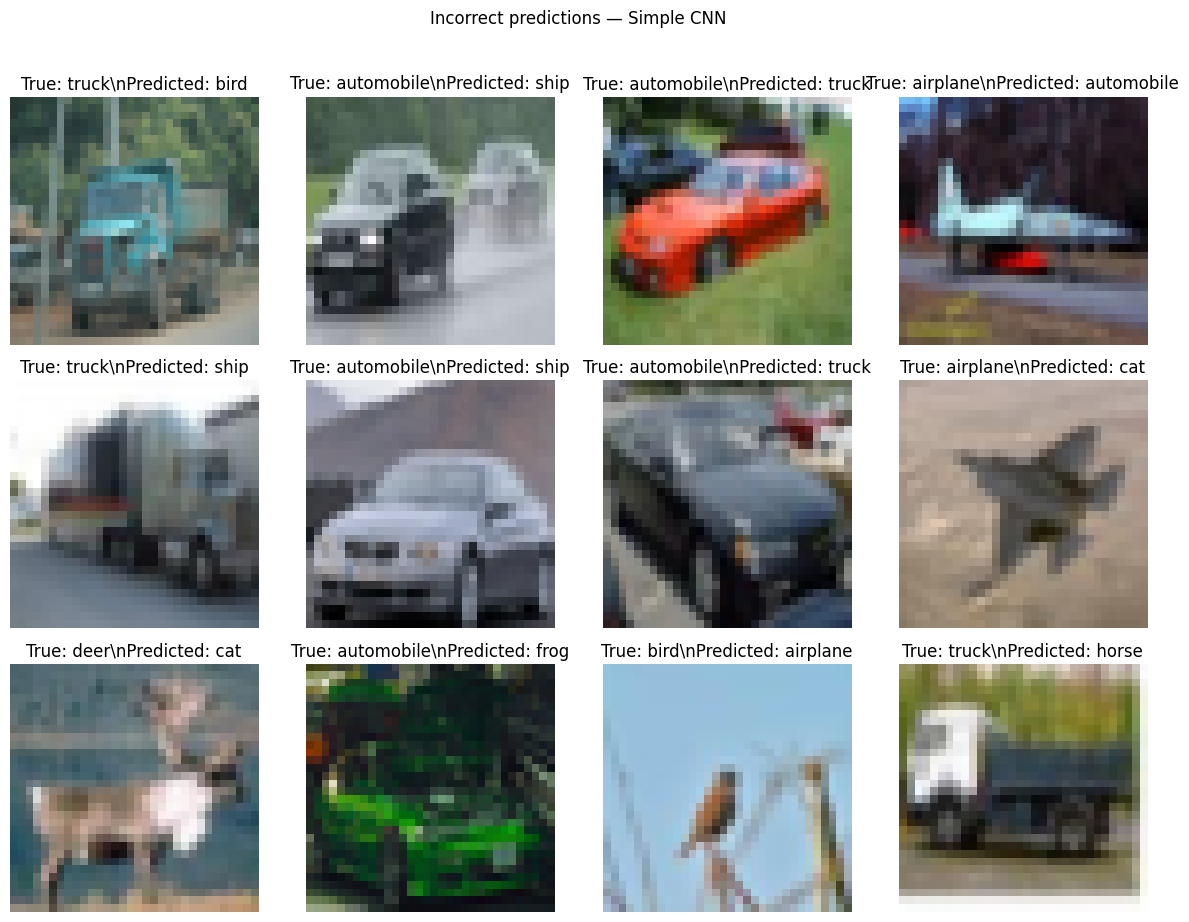

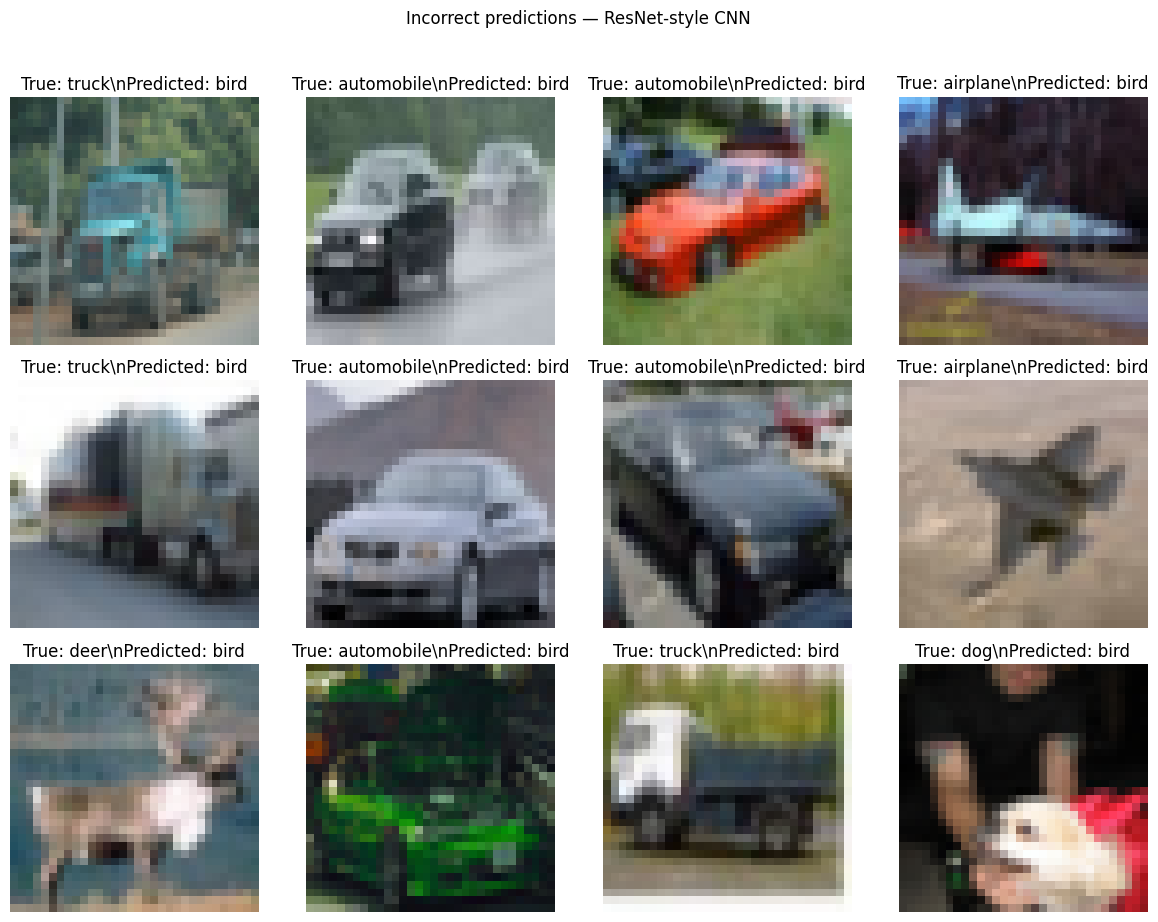

In [13]:
def show_misclassified(model_name, max_images=12):
    y_pred = predictions[model_name]
    wrong_indices = np.where(y_pred != y_test)[0][:max_images]

    if len(wrong_indices) == 0:
        print(f"No incorrect predictions found for {model_name} on this test subset.")
        return

    cols = 4
    rows = int(np.ceil(len(wrong_indices) / cols))
    plt.figure(figsize=(12, 3 * rows))

    for plot_idx, sample_idx in enumerate(wrong_indices, start=1):
        plt.subplot(rows, cols, plot_idx)
        plt.imshow(x_test[sample_idx])
        true_label = class_names[int(y_test[sample_idx])]
        predicted_label = class_names[int(y_pred[sample_idx])]
        plt.title(f"True: {true_label}\\nPredicted: {predicted_label}")
        plt.axis("off")

    plt.suptitle(f"Incorrect predictions — {model_name}", y=1.02)
    plt.tight_layout()
    plt.show()

show_misclassified("Simple CNN")
show_misclassified("ResNet-style CNN")

## 11. Automatically summarize the results

This cell uses the results measured in your current runtime. It does not invent accuracy values; the summary is generated from the models you trained.

In [14]:
best_row = results_df.iloc[0]
simple_row = results_df[results_df["Model"] == "Simple CNN"].iloc[0]
resnet_row = results_df[results_df["Model"] == "ResNet-style CNN"].iloc[0]

accuracy_difference = (
    resnet_row["Test accuracy (%)"] - simple_row["Test accuracy (%)"]
)

print("RESULT SUMMARY")
print("-" * 60)
print(f"Best test accuracy in this run: {best_row['Model']} "
      f"({best_row['Test accuracy (%)']:.2f}%)")
print(f"Simple CNN test accuracy: {simple_row['Test accuracy (%)']:.2f}%")
print(f"ResNet-style CNN test accuracy: {resnet_row['Test accuracy (%)']:.2f}%")
print(f"Accuracy difference (ResNet-style minus Simple CNN): "
      f"{accuracy_difference:+.2f} percentage points")
print(f"Simple CNN parameters: {int(simple_row['Total parameters']):,}")
print(f"ResNet-style CNN parameters: {int(resnet_row['Total parameters']):,}")
print("\\nConclusion guide:")
if accuracy_difference > 0:
    print("The ResNet-style model performed better on test accuracy in this run.")
elif accuracy_difference < 0:
    print("The Simple CNN performed better on test accuracy in this run.")
else:
    print("Both models achieved the same test accuracy in this run.")
print("Use the confusion matrices and classification reports to explain class-wise errors,")
print("and consider parameter count and training time when discussing complexity.")

RESULT SUMMARY
------------------------------------------------------------
Best test accuracy in this run: Simple CNN (28.00%)
Simple CNN test accuracy: 28.00%
ResNet-style CNN test accuracy: 12.70%
Accuracy difference (ResNet-style minus Simple CNN): -15.30 percentage points
Simple CNN parameters: 102,154
ResNet-style CNN parameters: 309,994
\nConclusion guide:
The Simple CNN performed better on test accuracy in this run.
Use the confusion matrices and classification reports to explain class-wise errors,
and consider parameter count and training time when discussing complexity.


## 12. Final assignment conclusion (complete after running)

Use the actual values from your output to complete this conclusion before submitting:

> In this assignment, a Simple CNN and a compact ResNet-style CNN were trained and tested using the same CIFAR-10 image dataset. The models were compared using test accuracy, test loss, parameter count, training time, confusion matrices, and classification reports. The **[model name]** achieved **[your test accuracy]%** test accuracy, while the **[other model name]** achieved **[your test accuracy]%**. The confusion matrices showed that **[mention one or two class pairs that were commonly confused]**. The Simple CNN has **[parameter count]** parameters, while the ResNet-style CNN has **[parameter count]** parameters. This experiment demonstrates that CNN architecture affects classification performance and prediction errors; however, the better model depends on the dataset, model design, and training setup.

### Limitations to mention honestly
- Quick-run mode uses only a subset of CIFAR-10, so results may be lower or less stable than a full-data experiment.
- The ResNet-style network demonstrates residual connections but is not a canonical ResNet-18/50.
- CIFAR-10 images are generic benchmark images, not a domain-specific dataset.
- Accuracy can vary with random initialization, runtime hardware, and training settings.